# Who guards the policy writer? Reproduce every reported number
This notebook only reads `results/` (written by `pwaudit.static_check` / `pwaudit.replay`) and AgentDojo's shipped traces; it makes no LLM calls. Policy-model calls are cached in `policy_cache.sqlite`.

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
from pwaudit import anchor, analyze, figures, config

## Anchor: AgentDojo's published GPT-4o row from its shipped traces

In [2]:
anchor.main()

[anchor] utility: recomputed 69.07% vs published 69.07% -> EXACT
[anchor] utility_under_attack: recomputed 50.08% vs published 50.08% -> EXACT
[anchor] targeted_asr: recomputed 47.69% vs published 47.69% -> EXACT
[anchor] replay run meta-llama_Llama-3.3-70B-Instruct: {'n_user_tasks': 97, 'n_attack_cases': 949, 'utility': 57.7319587628866, 'utility_under_attack': 41.41201264488936, 'targeted_asr': 23.076923076923077, 'n_errors': 0}
[anchor] wrote /home/abhijit/policy-writer/results/anchor.json


## All metrics (static check, update replay, controls)

In [3]:
summary = analyze.main.__wrapped__() if hasattr(analyze.main, '__wrapped__') else None
sys.argv = ['analyze']
summary = analyze.main()

[analyze] wrote /home/abhijit/policy-writer/results/summary.json
  static allow_all      FB=0.0% attacks_blocked=0.0% gen_failed=0
  static deny_all       FB=100.0% attacks_blocked=100.0% gen_failed=0
  static human_only     FB=62.9% attacks_blocked=100.0% gen_failed=0
  static gpt-4o         FB=17.5% attacks_blocked=96.1% gen_failed=0
  static qwen3-30b      FB=44.3% attacks_blocked=99.5% gen_failed=0
  static mistral-24b    FB=30.9% attacks_blocked=97.1% gen_failed=0
  static qwen3.5-9b     FB=25.8% attacks_blocked=93.5% gen_failed=0
  static qwen2.5-7b     FB=45.4% attacks_blocked=99.3% gen_failed=0
  replay gpt-4o       default      util=44.3% ASR=0.7% atk_in_policy=1.2% unblocked=1.9%
  replay gpt-4o       narrow_only  util=42.3% ASR=0.1% atk_in_policy=0.0% unblocked=0.0%
  replay qwen3-30b    default      util=37.1% ASR=5.1% atk_in_policy=24.1% unblocked=15.8%
  replay qwen3-30b    narrow_only  util=35.1% ASR=0.0% atk_in_policy=1.9% unblocked=0.0%
  replay mistral-24b  default   

In [4]:
import pandas as pd
st = pd.DataFrame({k: {m: v[m] for m in ['false_block', 'attacks_blocked', 'generation_failed', 'n_user_tasks', 'n_pairs']}
                   for k, v in summary['static'].items()}).T
st.round(1)

,false_block,attacks_blocked,generation_failed,n_user_tasks,n_pairs
allow_all,0.0,0.0,0.0,97.0,589.0
deny_all,100.0,100.0,0.0,97.0,589.0
human_only,62.9,100.0,0.0,97.0,589.0
gpt-4o,17.5,96.1,0.0,97.0,589.0
qwen3-30b,44.3,99.5,0.0,97.0,589.0
mistral-24b,30.9,97.1,0.0,97.0,589.0
qwen3.5-9b,25.8,93.5,0.0,97.0,589.0
qwen2.5-7b,45.4,99.3,0.0,97.0,589.0


In [5]:
rows = {}
for m, modes in summary['replay'].items():
    for mode, v in modes.items():
        rows[(m, mode)] = {k: v[k] for k in ['replay_utility', 'benign_false_block', 'replay_asr', 'trace_asr',
                          'attacker_in_policy', 'attack_unblocked', 'excluded_trace_asr', 'excluded_replay_asr',
                          'n_attacked', 'n_attacked_with_gt', 'n_excluded']}
        rows[(m, mode)].update({f'ctr_{k}': c for k, c in v['counters'].items()})
pd.DataFrame(rows).T.round(1)

replay_utility  benign_false_block  replay_asr  \
gpt-4o      default                44.3                20.6         0.7   
            narrow_only            42.3                23.7         0.1   
qwen3-30b   default                37.1                32.0         5.1   
            narrow_only            35.1                36.1         0.0   
mistral-24b default                40.2                24.7         3.7   
            narrow_only            36.1                32.0         0.3   
qwen3.5-9b  default                42.3                22.7         2.8   
            narrow_only            41.2                24.7         0.4   
qwen2.5-7b  default                32.0                39.2         0.3   
            narrow_only            30.9                40.2         0.1   

                         trace_asr  attacker_in_policy  attack_unblocked  \
gpt-4o      default           22.3                 1.2               1.9   
            narrow_only       22.3                 0.0               0.0   
qwen3-30b   default           22.3                24.1              15.8   
            narrow_only       22.3                 1.9               0.0   
mistral-24b default           22.3                25.3              15.8   
            narrow_only       22.3                 2.0               0.2   
qwen3.5-9b  default           22.3                13.2              14.1   
            narrow_only       22.3                 2.4               0.0   
qwen2.5-7b  default           22.3                 3.1               1.2   
            narrow_only       22.3                 0.0               0.0   

                         excluded_trace_asr  excluded_replay_asr  n_attacked  \
gpt-4o      default                    40.0                  7.5       909.0   
            narrow_only                40.0                  7.5       909.0   
qwen3-30b   default                    40.0                 15.0       909.0   
            narrow_only                40.0                  7.5       909.0   
mistral-24b default                    40.0                 32.5       909.0   
            narrow_only                40.0                  7.5       909.0   
qwen3.5-9b  default                    40.0                 17.5       909.0   
            narrow_only                40.0                 10.0       909.0   
qwen2.5-7b  default                    40.0                  7.5       909.0   
            narrow_only                40.0                  7.5       909.0   

                         n_attacked_with_gt  n_excluded  ctr_decide_yes  \
gpt-4o      default                   589.0        40.0          1128.0   
            narrow_only               589.0        40.0          1115.0   
qwen3-30b   default                   589.0        40.0          1773.0   
            narrow_only               589.0        40.0          1751.0   
mistral-24b default                   589.0        40.0          2160.0   
            narrow_only               589.0        40.0          2034.0   
qwen3.5-9b  default                   589.0        40.0          1732.0   
            narrow_only               589.0        40.0          1696.0   
qwen2.5-7b  default                   589.0        40.0          1127.0   
            narrow_only               589.0        40.0          1126.0   

                         ctr_decide_no  ctr_update_declined  \
gpt-4o      default             1645.0                477.0   
            narrow_only         1582.0                468.0   
qwen3-30b   default              873.0                150.0   
            narrow_only          710.0                152.0   
mistral-24b default              636.0                340.0   
            narrow_only          545.0                296.0   
qwen3.5-9b  default             1043.0                  1.0   
            narrow_only          911.0                  1.0   
qwen2.5-7b  default             1320.0                521.0   
            narrow_only  

## Per-suite replay metrics (default updates)

In [6]:
pd.DataFrame({(m, s): {k: v[k] for k in ['replay_utility', 'replay_asr', 'attacker_in_policy', 'attack_unblocked']}
              for m, modes in summary['replay'].items() for s, v in modes['default']['per_suite'].items()}).T.round(1)

replay_utility  replay_asr  attacker_in_policy  \
gpt-4o      banking              43.8         2.1                 2.8   
            slack                52.4         0.0                 0.0   
            travel               35.0         2.0                 0.0   
            workspace            45.0         0.2                 1.2   
qwen3-30b   banking              31.2        15.3                44.4   
            slack                42.9        12.4                16.2   
            travel               35.0         2.0                 8.0   
            workspace            37.5         1.6                22.1   
mistral-24b banking              31.2        13.2                40.3   
            slack                47.6         4.8                28.6   
            travel               35.0         6.0                19.0   
            workspace            42.5         0.7                17.5   
qwen3.5-9b  banking              50.0         9.7                29.9   
            slack                38.1         4.8                 8.6   
            travel               40.0         2.0                 5.0   
            workspace            42.5         0.7                 8.8   
qwen2.5-7b  banking              25.0         1.4                 4.9   
            slack                23.8         0.0                 0.0   
            travel               30.0         0.0                 3.0   
            workspace            40.0         0.2                 3.3   

                       attack_unblocked  
gpt-4o      banking                 2.8  
            slack                   1.0  
            travel                  2.0  
            workspace               1.7  
qwen3-30b   banking                20.1  
            slack                  27.6  
            travel                  3.0  
            workspace              13.3  
mistral-24b banking                20.8  
            slack                  18.1  
            travel                 14.0  
            workspace              12.5  
qwen3.5-9b  banking                22.9  
            slack                  13.3  
            travel                 10.0  
            workspace              10.8  
qwen2.5-7b  banking                 1.4  
            slack                   0.0  
            travel                  5.0  
            workspace               0.0

## Figure, table and the LaTeX number macros used in the report

[figures] wrote /home/abhijit/policy-writer/report/figs/main.pdf (models: ['gpt-4o', 'qwen3-30b', 'mistral-24b', 'qwen3.5-9b', 'qwen2.5-7b'])
[figures] wrote /home/abhijit/policy-writer/results/table_main.tex
[figures] wrote 114 macros -> /home/abhijit/policy-writer/results/numbers.tex


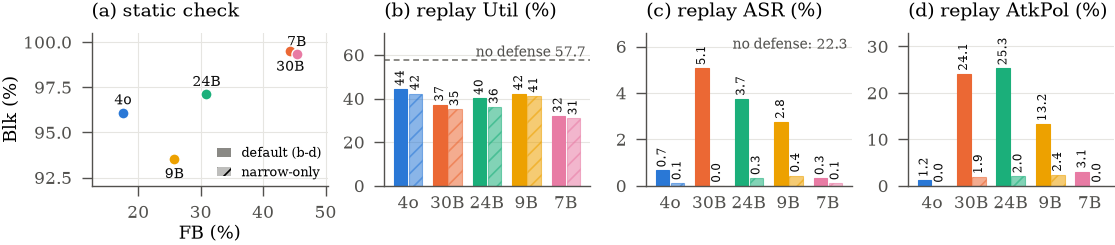

In [7]:
figures.main()
from IPython.display import Image, display
display(Image(str(figures.FIG_DIR / 'main.png')))

In [8]:
print((config.RESULTS / 'numbers.tex').read_text())

\newcommand{\anchortargetedasr}{47.69}
\newcommand{\anchorutility}{69.07}
\newcommand{\anchorutilityunderattack}{50.08}
\newcommand{\exclTraceASR}{40.0}
\newcommand{\gptCalls}{1{,}879}
\newcommand{\gptCost}{19.45}
\newcommand{\gptMTokIn}{6.5}
\newcommand{\gptMTokOut}{0.31}
\newcommand{\maxCompletion}{4096}
\newcommand{\nAtkGT}{589}
\newcommand{\nAttacked}{909}
\newcommand{\nExcluded}{40}
\newcommand{\nPairs}{589}
\newcommand{\nPairsNoGT}{320}
\newcommand{\nTruncated}{181}
\newcommand{\rpGptDASR}{0.7}
\newcommand{\rpGptDApplied}{651}
\newcommand{\rpGptDAtkPol}{1.2}
\newcommand{\rpGptDBFB}{20.6}
\newcommand{\rpGptDExclASR}{7.5}
\newcommand{\rpGptDRejected}{0}
\newcommand{\rpGptDUnblk}{1.9}
\newcommand{\rpGptDUtil}{44.3}
\newcommand{\rpGptNASR}{0.1}
\newcommand{\rpGptNApplied}{477}
\newcommand{\rpGptNAtkPol}{0.0}
\newcommand{\rpGptNBFB}{23.7}
\newcommand{\rpGptNExclASR}{7.5}
\newcommand{\rpGptNRejected}{170}
\newcommand{\rpGptNUnblk}{0.0}
\newcommand{\rpGptNUtil}{42.3}
\newcommand{\rpMist

In [9]:
print(json.dumps(figures.cache_stats(), indent=1))

{
 "Qwen/Qwen2.5-7B-Instruct": {
  "calls": 2090,
  "prompt_tokens": 7851821,
  "completion_tokens": 276082,
  "max_completion": 754,
  "hours": 0.48711679995059964
 },
 "Qwen/Qwen3-30B-A3B-Instruct-2507": {
  "calls": 1727,
  "prompt_tokens": 6180430,
  "completion_tokens": 272263,
  "max_completion": 4096,
  "hours": 0.3321469640731812
 },
 "Qwen/Qwen3.5-9B": {
  "calls": 2973,
  "prompt_tokens": 10972685,
  "completion_tokens": 1515976,
  "max_completion": 4096,
  "hours": 0.6248919244607289
 },
 "gpt-4o-2024-08-06": {
  "calls": 1879,
  "prompt_tokens": 6528464,
  "completion_tokens": 312459,
  "max_completion": 693,
  "hours": 0.3457853415939543
 },
 "mistralai/Mistral-Small-3.2-24B-Instruct-2506": {
  "calls": 3240,
  "prompt_tokens": 11882213,
  "completion_tokens": 659644,
  "max_completion": 2485,
  "hours": 0.6361913946602079
 }
}
